# Marketing Mix Modeling in Python, Step by Step

*Brian James Curry, Vector 1 · [vector1.ai](https://vector1.ai) · November 2026*

This notebook builds a marketing mix model (MMM) from scratch on **synthetic data where the true answer is known**. That is the point: on real data you never learn whether a model recovered the truth, so you can't tell a good model from a confident one. Here you can.

You will:

1. Simulate two years of weekly sales driven by three media channels, with carryover (adstock), diminishing returns (saturation), trend, seasonality and promotions.
2. Fit a model that estimates carryover, saturation and each channel's effect.
3. Check the recovered return on investment (ROI) against the truth.
4. See what goes wrong when the model leaves carryover out.
5. Read the response curves to answer the budget question.

It needs only `numpy`, `pandas`, `scipy` and `matplotlib`, so it runs as is in Google Colab. A Bayesian version with PyMC-Marketing is sketched at the end.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

rng = np.random.default_rng(42)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1. The two building blocks: adstock and saturation

**Adstock** captures carryover: a TV flight this week still moves sales next week. Geometric adstock keeps a share `decay` of last week's effect.

**Saturation** captures diminishing returns: the tenth thousand dollars buys less than the first. The Hill curve rises quickly, then flattens; `half` is the spend level that delivers half of the maximum effect.

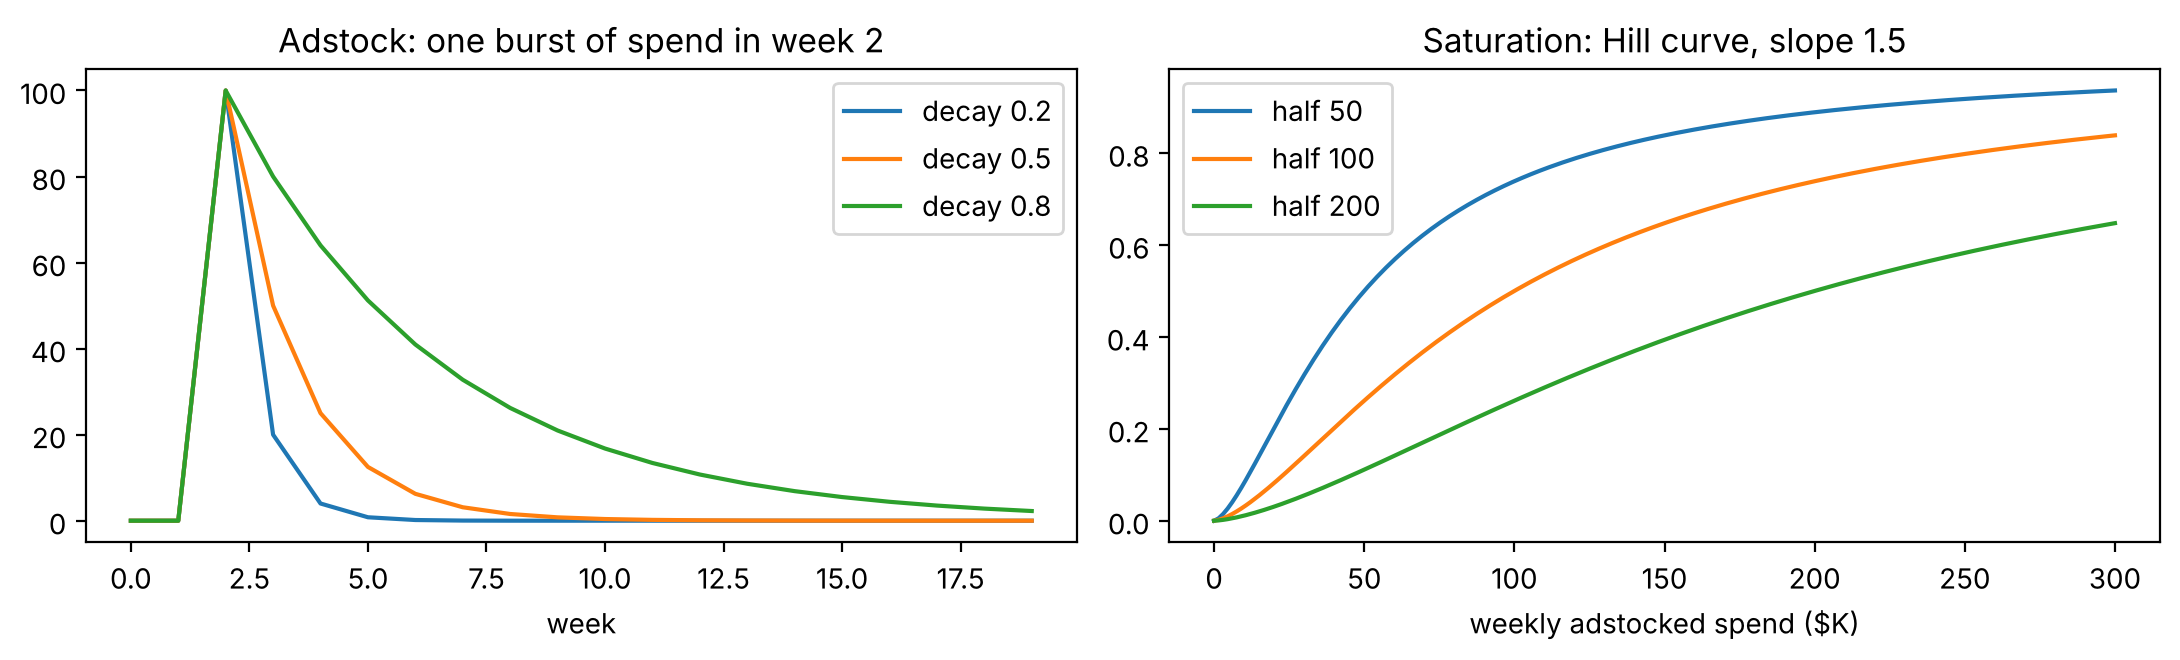

In [2]:
def adstock(x, decay):
    out = np.zeros_like(x, dtype=float)
    carry = 0.0
    for t, v in enumerate(x):
        carry = v + decay * carry
        out[t] = carry
    return out

def hill(x, half, slope):
    x = np.maximum(x, 0)
    return x**slope / (x**slope + half**slope)

x = np.linspace(0, 300, 200)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
pulse = np.zeros(20); pulse[2] = 100
for d in (0.2, 0.5, 0.8):
    ax[0].plot(adstock(pulse, d), label=f"decay {d}")
ax[0].set_title("Adstock: one burst of spend in week 2"); ax[0].set_xlabel("week"); ax[0].legend()
for h in (50, 100, 200):
    ax[1].plot(x, hill(x, h, 1.5), label=f"half {h}")
ax[1].set_title("Saturation: Hill curve, slope 1.5"); ax[1].set_xlabel("weekly adstocked spend ($K)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 2. Simulate two years of sales with known effects

Three channels with different behavior:

| Channel | Carryover (decay) | Half-saturation ($K) | Max weekly effect ($K sales) |
|---|---|---|---|
| TV | 0.6 (long) | 120 | 380 |
| Search | 0.1 (short) | 40 | 260 |
| Social | 0.35 | 60 | 150 |

Every channel has some weeks at or near zero spend. That's deliberate: a channel that never pauses is hard to separate from the baseline (more on that in section 7).

Sales also include a baseline, a slow upward trend, yearly seasonality, a promotion flag and noise. Because we set every number, we can compute each channel's **true** contribution and ROI.

True ROI (sales per $1 of spend):
tv       3.15
search   3.00
social   1.50


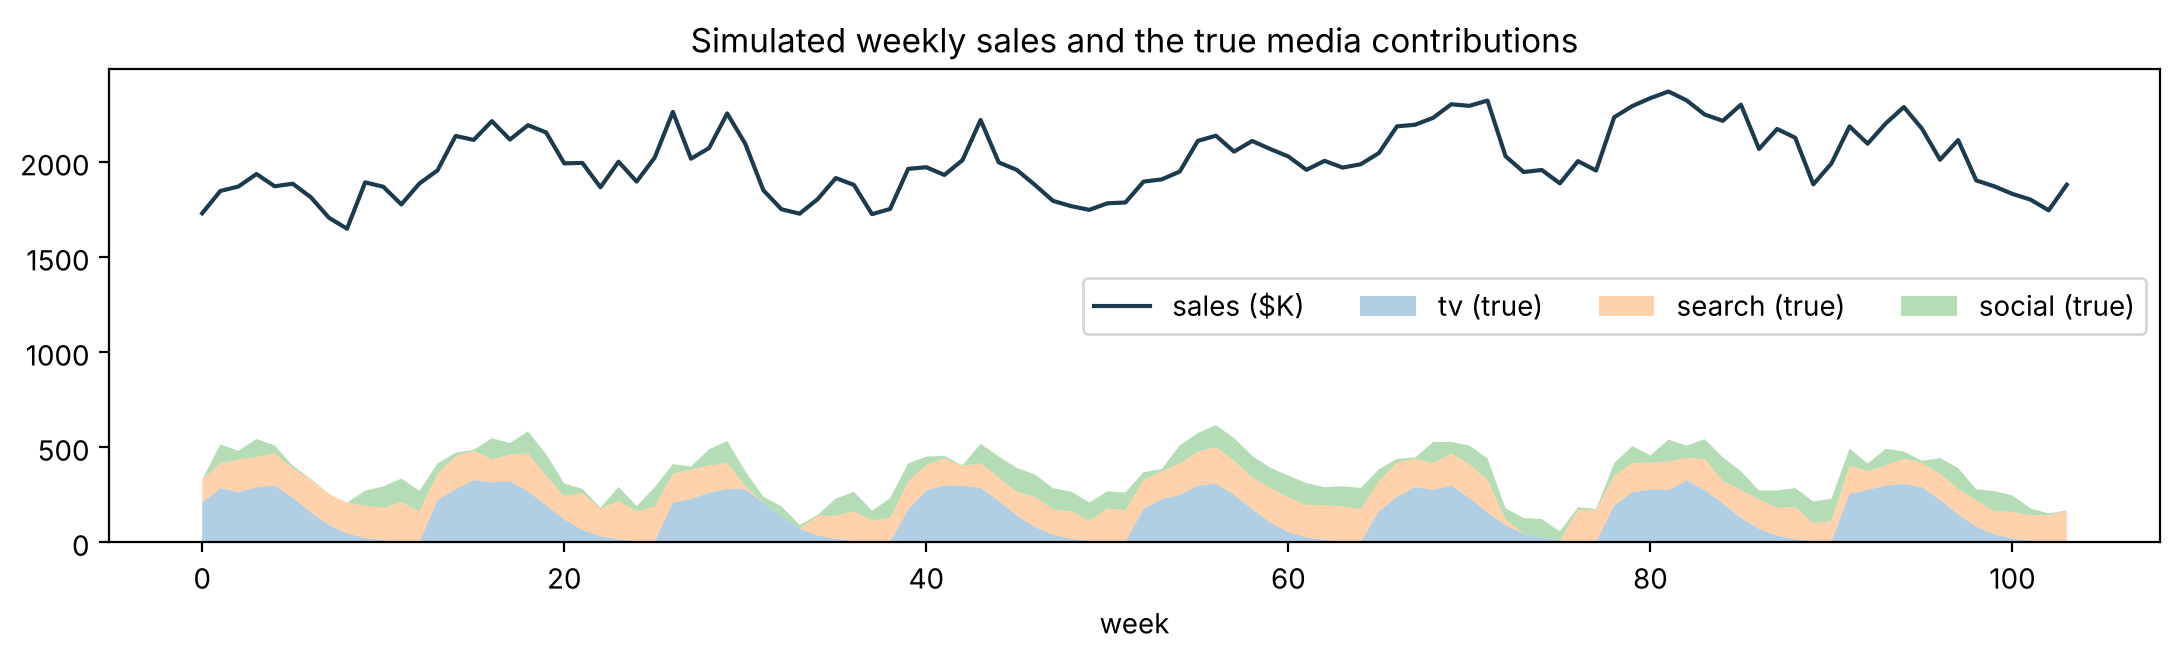

In [3]:
weeks = 104
t = np.arange(weeks)
true = {
    "tv":     dict(decay=0.60, half=120.0, slope=1.6, beta=380.0),
    "search": dict(decay=0.10, half=40.0,  slope=1.2, beta=260.0),
    "social": dict(decay=0.35, half=60.0,  slope=1.4, beta=150.0),
}

# Spend in $K per week: TV in flights, search on with a seasonal swing and two planned four-week pauses, social on in about 60% of weeks
tv = np.where((t % 13) < 5, rng.gamma(9, 14, weeks), 0.0)
search = rng.gamma(12, 4, weeks) * (1 + 0.3 * np.sin(2 * np.pi * t / 52))
search[(t >= 30) & (t < 34) | (t >= 72) & (t < 76)] = 0.0   # two planned dark periods
social = np.where(rng.random(weeks) < 0.6, np.clip(rng.normal(85, 30, weeks), 10, None), 0.0)
spend = pd.DataFrame({"tv": tv, "search": search, "social": social})

promo = (rng.random(weeks) < 0.12).astype(float)
base, trend, season_amp, promo_lift = 1500.0, 2.5, 140.0, 120.0
season = season_amp * np.sin(2 * np.pi * (t - 10) / 52)

contrib = pd.DataFrame({c: p["beta"] * hill(adstock(spend[c].values, p["decay"]), p["half"], p["slope"])
                        for c, p in true.items()})
noise = rng.normal(0, 45, weeks)
sales = base + trend * t + season + promo_lift * promo + contrib.sum(axis=1).values + noise

df = spend.assign(promo=promo, sales=sales)
true_roi = contrib.sum() / spend.sum()
print("True ROI (sales per $1 of spend):")
print(true_roi.round(2).to_string())

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(df["sales"], color="#1d3b4f", label="sales ($K)")
ax.stackplot(t, contrib.T.values, labels=[f"{c} (true)" for c in contrib], alpha=0.35)
ax.set_title("Simulated weekly sales and the true media contributions"); ax.set_xlabel("week"); ax.legend(ncol=4)
plt.tight_layout(); plt.show()

## 3. Fit the model

The model has the same structure as the simulation, but every parameter is unknown: a decay, half-saturation and effect size per channel, plus intercept, trend, two seasonality terms and the promotion lift. We fit by nonlinear least squares with bounds that keep the parameters sensible, and restart from several random starting points because the problem is not convex.

Hold out the last 12 weeks to check the fit on data the model hasn't seen.

Training MAPE 1.6%   Holdout MAPE (last 12 weeks) 1.8%


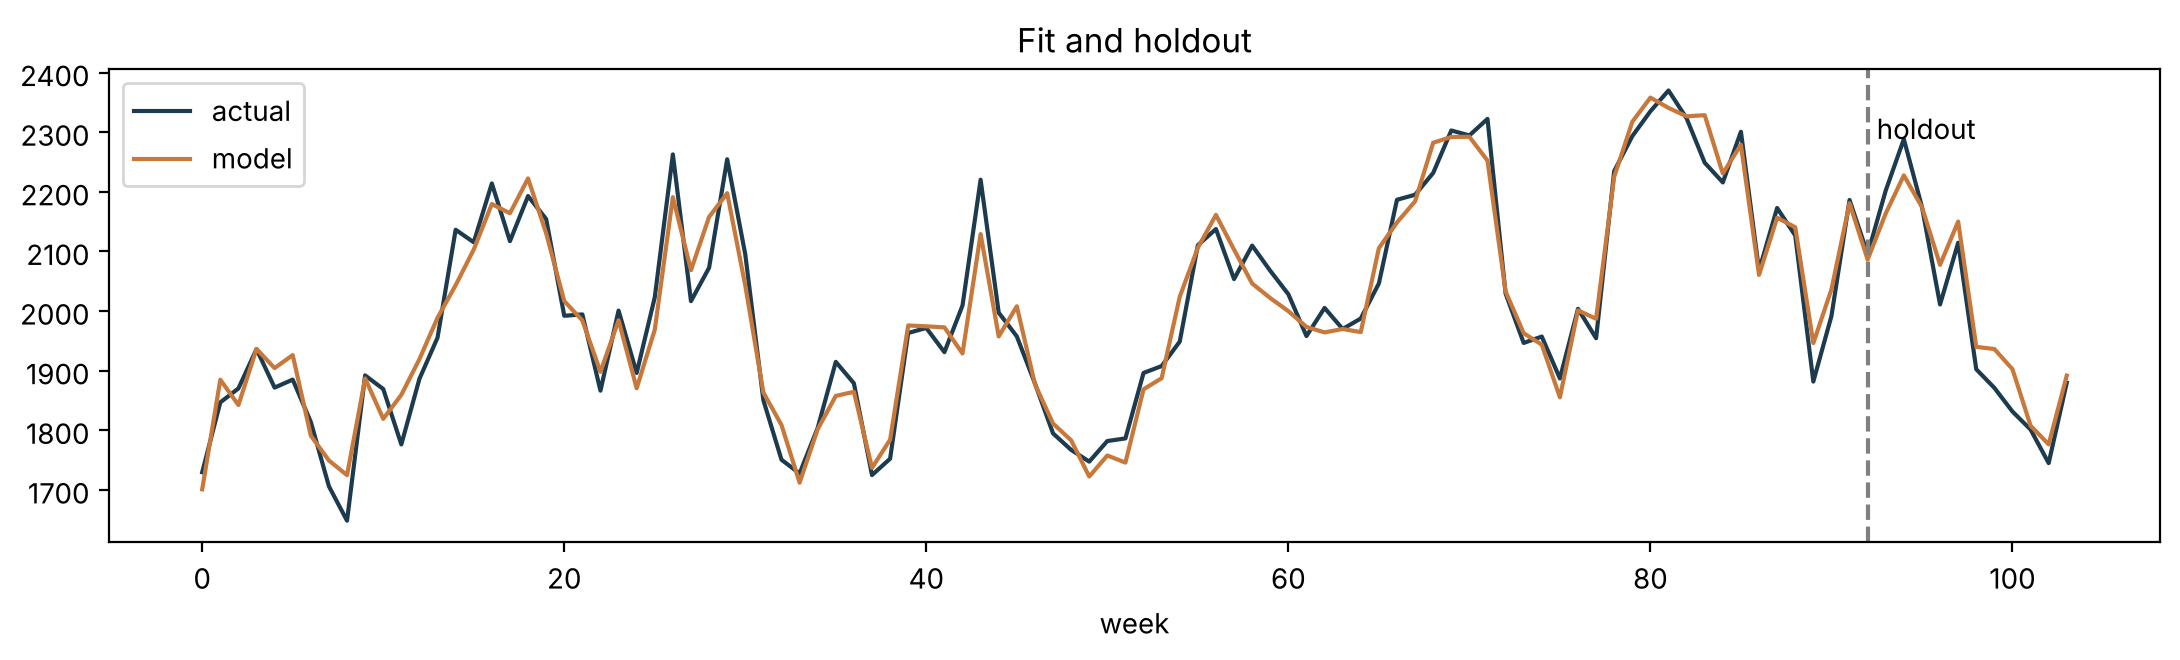

In [4]:
channels = list(true)
train = np.arange(weeks) < weeks - 12
s1, c1 = np.sin(2 * np.pi * t / 52), np.cos(2 * np.pi * t / 52)

def unpack(theta):
    k = len(channels)
    dec, half, slope, beta = theta[:k], theta[k:2*k], theta[2*k:3*k], theta[3*k:4*k]
    a0, a_tr, a_s, a_c, a_p = theta[4*k:]
    return dec, half, slope, beta, (a0, a_tr, a_s, a_c, a_p)

def media(theta, use_adstock=True):
    dec, half, slope, beta, _ = unpack(theta)
    cols = {}
    for i, c in enumerate(channels):
        x = adstock(df[c].values, dec[i]) if use_adstock else df[c].values
        cols[c] = beta[i] * hill(x, half[i], slope[i])
    return pd.DataFrame(cols)

def predict(theta, use_adstock=True):
    *_, (a0, a_tr, a_s, a_c, a_p) = unpack(theta)
    return a0 + a_tr * t + a_s * s1 + a_c * c1 + a_p * promo + media(theta, use_adstock).sum(axis=1).values

def fit(use_adstock=True, restarts=12):
    k = len(channels)
    lo = [0.0]*k + [5.0]*k + [0.7]*k + [0.0]*k + [0, -20, -500, -500, -500]
    hi = [0.95]*k + [500.0]*k + [3.0]*k + [2000.0]*k + [5000, 20, 500, 500, 1000]
    if not use_adstock:
        hi[:k] = [1e-6]*k
    best = None
    for _ in range(restarts):
        x0 = [rng.uniform(l, h) if h - l < 1e3 else rng.uniform(l, l + 500) for l, h in zip(lo, hi)]
        r = least_squares(lambda th: (predict(th, use_adstock) - df["sales"].values)[train], x0,
                          bounds=(lo, hi), max_nfev=4000)
        if best is None or r.cost < best.cost:
            best = r
    return best.x

theta = fit()
pred = predict(theta)
mape = lambda m: np.mean(np.abs(pred[m] - df["sales"].values[m]) / df["sales"].values[m])
print(f"Training MAPE {mape(train):.1%}   Holdout MAPE (last 12 weeks) {mape(~train):.1%}")

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(df["sales"], color="#1d3b4f", label="actual")
ax.plot(pred, color="#c7783a", label="model")
ax.axvline(weeks - 12, color="grey", ls="--"); ax.text(weeks - 11.5, ax.get_ylim()[1]*0.97, "holdout", va="top")
ax.set_title("Fit and holdout"); ax.set_xlabel("week"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Did it recover the truth?

A good fit is not the goal; recovering the true channel effects is. Compare the estimated carryover and ROI with the values we simulated.

In [5]:
dec, half, slope, beta, _ = unpack(theta)
est_roi = media(theta).sum() / spend.sum()
check = pd.DataFrame({
    "true decay": [true[c]["decay"] for c in channels],
    "estimated decay": dec,
    "true ROI": true_roi.values,
    "estimated ROI": est_roi.values,
}, index=channels)
check["ROI error"] = (check["estimated ROI"] / check["true ROI"] - 1).map(lambda v: f"{v:+.0%}")
check

,true decay,estimated decay,true ROI,estimated ROI,ROI error
tv,0.60,0.61,3.15,4.34,+38%
search,0.10,0.10,3.00,3.70,+24%
social,0.35,0.43,1.50,1.38,-8%


**Reading it.** The carryover estimates land almost exactly on the truth, and the ROI ranking is right: TV and search return more per dollar than social. The ROI levels are less exact. TV and search come out roughly 25% to 40% too high and social a little low, even though the model misses holdout sales by under 2%. A single best-fit answer can split credit between media and the baseline wrongly while fitting beautifully. That is why section 7 adds uncertainty ranges and lift-test calibration, and why a good fit on its own proves little.

## 5. What goes wrong without adstock

Many quick MMMs regress sales on same-week spend. Refit with carryover switched off and compare. A channel with long carryover, like TV, loses the sales that arrive in the weeks after it airs, so its ROI is understated; here it falls to less than half its true value. A budget built on that model would cut the channel that pays back best.

        true ROI  with adstock  without adstock
tv          3.15          4.34             1.48
search      3.00          3.70             2.25
social      1.50          1.38             0.94


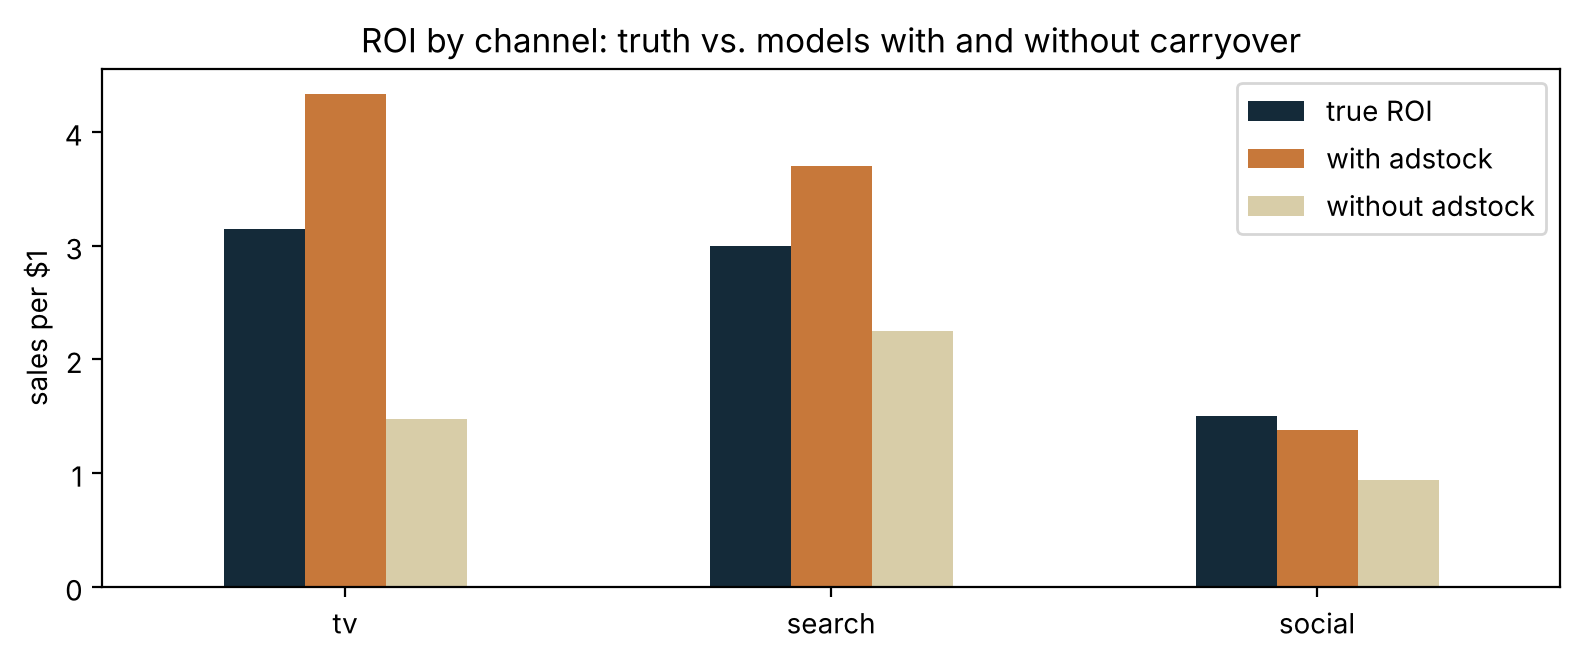

In [6]:
theta_no = fit(use_adstock=False)
roi_no = media(theta_no, use_adstock=False).sum() / spend.sum()
comp = pd.DataFrame({"true ROI": true_roi, "with adstock": est_roi, "without adstock": roi_no})
print(comp.round(2).to_string())
ax = comp.plot.bar(figsize=(8, 3.4), color=["#142a39", "#c7783a", "#d8cda8"], rot=0)
ax.set_title("ROI by channel: truth vs. models with and without carryover"); ax.set_ylabel("sales per $1")
plt.tight_layout(); plt.show()

## 6. The budget question: response curves and marginal ROI

Average ROI says how a channel paid back overall. The budget question needs **marginal** ROI: what the next dollar buys at today's spend. Response curves show both. Where the curve is flat, more money buys little.

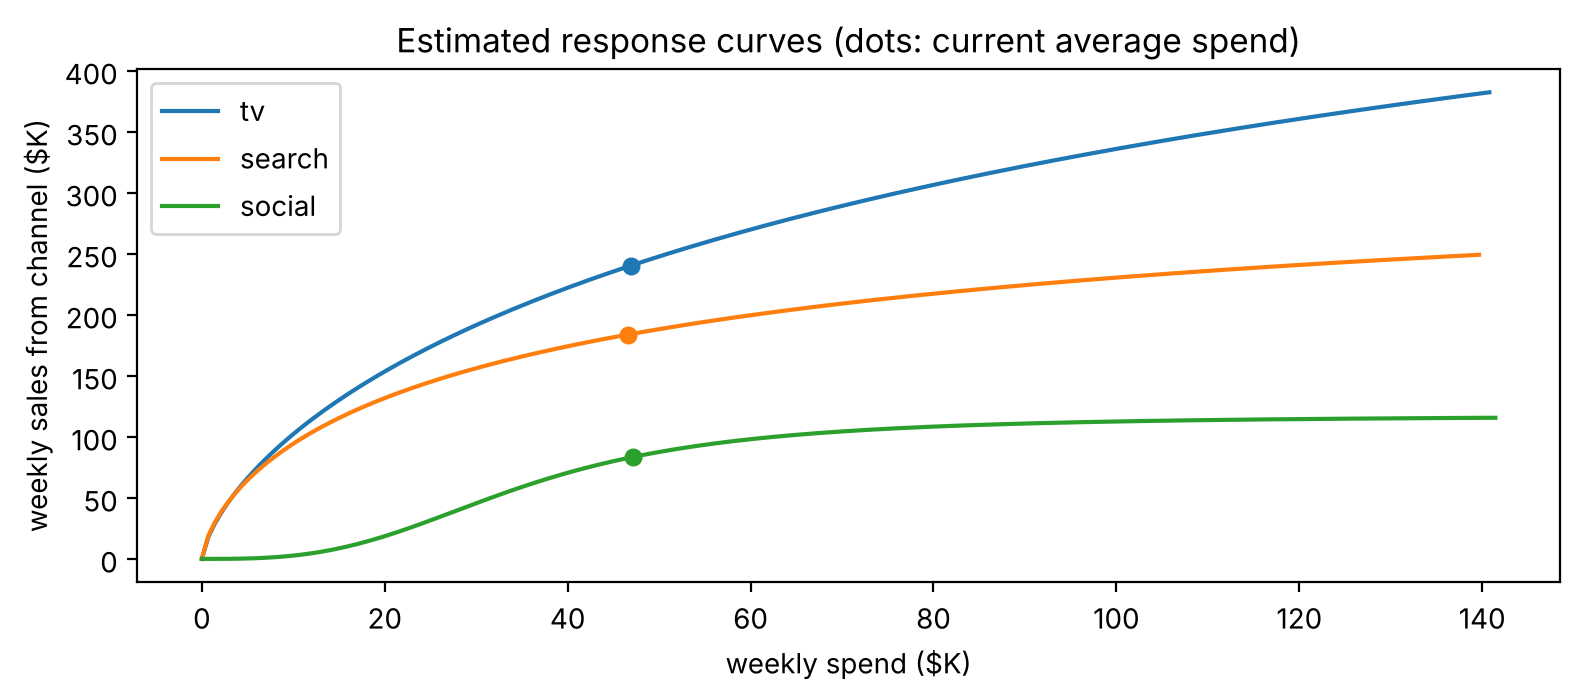

,avg weekly spend ($K),marginal ROI at current spend
channel,,
tv,46.93,2.47
search,46.55,1.35
social,47.14,1.52


In [7]:
def steady_state_response(c, weekly_spend, th):
    i = channels.index(c)
    d, h, s, b, _ = unpack(th)
    carried = weekly_spend / (1 - d[i])          # adstock level under constant weekly spend
    return b[i] * hill(carried, h[i], s[i])

fig, ax = plt.subplots(figsize=(8, 3.6))
rows = []
for c in channels:
    grid = np.linspace(0, spend[c].mean() * 3, 200)
    resp = steady_state_response(c, grid, theta)
    ax.plot(grid, resp, label=c)
    now = spend[c].mean()
    marg = (steady_state_response(c, now * 1.01, theta) - steady_state_response(c, now, theta)) / (now * 0.01)
    ax.scatter([now], [steady_state_response(c, now, theta)], s=30)
    rows.append((c, now, marg))
ax.set_xlabel("weekly spend ($K)"); ax.set_ylabel("weekly sales from channel ($K)")
ax.set_title("Estimated response curves (dots: current average spend)"); ax.legend()
plt.tight_layout(); plt.show()
pd.DataFrame(rows, columns=["channel", "avg weekly spend ($K)", "marginal ROI at current spend"]).set_index("channel")

**Reading it.** A channel whose marginal ROI is above 1 still returns more than it costs at the margin; one below 1 is past the point where the next dollar pays for itself. Shift budget toward the higher marginal ROI until the margins meet, and test the move with a holdout or geo-lift experiment before committing the full budget.

## 7. Where to go next

- **Uncertainty.** Least squares gives one answer. A Bayesian MMM gives a range for every ROI, which matters when channels move together. With PyMC-Marketing the same structure is a few lines:

```python
# pip install pymc-marketing
from pymc_marketing.mmm import MMM, GeometricAdstock, LogisticSaturation
mmm = MMM(date_column="week", channel_columns=["tv", "search", "social"],
          control_columns=["promo"], adstock=GeometricAdstock(l_max=8),
          saturation=LogisticSaturation(), yearly_seasonality=2)
# mmm.fit(X, y)  # X: a DataFrame with a "week" date column, the spend columns and promo
```

- **Collinearity.** If a channel's spend rises steadily over time, the model can't tell its effect from the sales trend. Try it: add `+ 0.25 * t` to `social` in step 2 and refit; its ROI estimate goes badly wrong while the fit still looks excellent. Real budgets often drift like this, which is why a good fit proves little. The same goes for a channel that never pauses and barely varies: its steady effect blends into the baseline, so plan spend variation (or a test) into the media calendar.
- **Calibration.** Use lift tests to anchor the channels the model can't separate.
- **Benchmarking.** Run any MMM on simulated data like this before trusting it on yours. [Papilon](https://github.com/Bodhi8/papilon) is an open-source Python MMM built around that idea.

More research, interactive demos and code: [vector1.ai](https://vector1.ai).